In [ ]:
import pandas as pd
import pandas as pd
from tqdm import tqdm
from openai import OpenAI

#Read Data


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
output_file = "/content/drive/MyDrive/fix_systematic_review/MMAT/final_Type_jugment.xlsx"
df = pd.read_excel(output_file)

In [ ]:
import pickle

with open("/content/drive/MyDrive/fix_systematic_review/134_texts.pkl", "rb") as f:
    file_texts = pickle.load(f)


#Create dict to 5 questions


In [ ]:
questions_dict = {
    "Qualitative": [
        "Is the qualitative approach appropriate to answer the research question?",
        "Are the qualitative data collection methods adequate to address the research question?",
        "Are the findings adequately derived from the data?",
        "Is the interpretation of results sufficiently substantiated by data?",
        "Is there coherence between qualitative data sources, collection, analysis and interpretation?"
    ],
    "Quantitative_randomized_controlled_trials": [
        "Is randomization appropriately performed?",
        "Are the groups comparable at baseline?",
        "Are there complete outcome data?",
        "Are outcome assessors blinded to the intervention provided?",
        "Did the participants adhere to the assigned intervention?"
    ],
    "Quantitative_non_randomized": [
        "Are the participants representative of the target population?",
        "Are measurements appropriate regarding both the outcome and intervention (or exposure)?",
        "Are there complete outcome data?",
        "Are the confounders accounted for in the design and analysis?",
        "During the study period, is the intervention administered (or exposure occurred) as intended?"
    ],
    "Quantitative_descriptive": [
        "Is the sampling strategy relevant to address the research question?",
        "Is the sample representative of the target population?",
        "Are the measurements appropriate?",
        "Is the risk of nonresponse bias low?",
        "Is the statistical analysis appropriate to answer the research question?"
    ],
    "Mixed_methods": [
        "Is there an adequate rationale for using a mixed methods design to address the research question?",
        "Are the different components of the study effectively integrated to answer the research question?",
        "Are the outputs of the integration of qualitative and quantitative components adequately interpreted?",
        "Are divergences and inconsistencies between quantitative and qualitative results adequately addressed?",
        "Do the different components of the study adhere to the quality criteria of each tradition of the methods involved?"
    ]
}




In [ ]:
prompt_tamplate = """
You are an expert in systematic reviews.

Text to evaluate:
{text}

Task:
{task}
Respond in the exact format:
Answer: <Yes or No or Can’t tell>
Comments: <One to three sentences explaining your reasoning>
"""

prompt_tamplate = """
You are an expert in systematic reviews.

Text to evaluate:
{text}

Task:
{task}
Respond in the exact format:
Answer: <Yes or No or Can’t tell>
Comments: <If possible, provide a direct quote or evidence from the text supporting your answer.
If no direct quote is available, give a short explanation (1–3 sentences) based on the text.>
"""


#gpt-4o-mini

In [ ]:
import pandas as pd
import re
from openai import OpenAI

client = OpenAI(api_key="key_api")



def call_openai(prompt, model="gpt-4o-mini"):
    try:
        response = client.chat.completions.create(
            model=model,
            messages=[{"role": "user", "content": prompt}],
         temperature=0,
    max_tokens=2048,
    top_p=0.45
        )
        return response.choices[0].message.content.strip()
    except Exception as e:
        return f"Error: {e}"




In [ ]:
from tqdm import tqdm
import time

# Column names
type_col = "Type_final"               # Column with MMAT type (e.g., "Qualitative", "Mixed methods")
text_col = "Matching_Filename"  # Column with the filename to get text from
out_prefix = "MMAT_Q"           # Prefix for output columns (MMAT_Q1 ... MMAT_Q5)

# Save settings
save_interval = 10              # Save progress every N rows
output_file = "/content/drive/MyDrive/fix_systematic_review/MMAT/MMAT/mmat_progress_gpt_2.xlsx"  # Path to save progress file

# Create empty columns for MMAT_Q1 ... MMAT_Q5
for qi in range(1, 6):
    df[f"{out_prefix}{qi}_gpt"] = ""

start_time = time.time()

# Loop over DataFrame rows with tqdm progress bar
for i, row in tqdm(df.iterrows(), total=len(df), desc="Processing rows"):
    tp = row.get(type_col, None)       # Get MMAT type for this row
    number_id = row.get(text_col, None) # Get filename for this row

    # Skip if the type is not in our question dictionary
    if tp not in questions_dict:
        continue

    questions = questions_dict[tp]  # Get the 5 relevant MMAT questions

    # Loop through each question for this type
    for qi, task in enumerate(questions, start=1):
        # Prepare the prompt with the text and the current question
        prompt = prompt_tamplate.format(text=file_texts[number_id], task=task)
        # Send prompt to the model and get the result
        result = call_openai(prompt)

        # Save the result in the corresponding MMAT_Q column
        df.at[i, f"{out_prefix}{qi}_gpt"] = result

    # Save progress every 'save_interval' rows
    if i % save_interval == 0 and i > 0:
        df.to_excel(output_file, index=False)
        print(f"💾 Progress saved at row {i} to {output_file}")
# Final save after processing all rows
df.to_excel(output_file, index=False)
print(f"✅ Processing completed. Final file saved to {output_file}")


#Llama

In [ ]:
import os
import requests
import json

# Store your API key as an environment variable for safety:
OPENROUTER_API_KEY = 'key_api'
OPENROUTER_URL = "https://openrouter.ai/api/v1/chat/completions"

HEADERS = {
    "Authorization": f"Bearer {OPENROUTER_API_KEY}",
    "Content-Type": "application/json",
    # Optional but recommended: helps OpenRouter show where requests come from
    "HTTP-Referer": "https://your-site-or-none.example",
    "X-Title": "Your App Name",
}

def call_openai_new(prompt, model="meta-llama/llama-3.3-70b-instruct", #"google/gemini-2.5-flash-lite"
                temperature=0, top_p=0.45, max_tokens=2048, timeout=60):
    """
    Replacement function for OpenAI client -> uses OpenRouter API.

    Args:
        prompt (str): user input text
        model (str): model to use (default Gemini Flash Lite)
        temperature (float): sampling temperature
        top_p (float): nucleus sampling
        max_tokens (int): maximum output tokens
        timeout (int): request timeout in seconds

    Returns:
        str: model's response content or error message
    """
    try:
        payload = {
            "model": model,
            "messages": [
                {"role": "user", "content": prompt}
            ],
            "temperature": temperature,
            "top_p": top_p,
            "max_tokens": max_tokens,
        }

        resp = requests.post(OPENROUTER_URL, headers=HEADERS,
                             data=json.dumps(payload), timeout=timeout)
        resp.raise_for_status()  # raises HTTPError if status != 200
        data = resp.json()

        # OpenRouter returns a format similar to OpenAI
        return data["choices"][0]["message"]["content"].strip()

    except requests.HTTPError as e:
        # Try to parse error body for more details
        try:
            err_body = resp.json()
        except Exception:
            err_body = resp.text
        return f"Error {resp.status_code}: {err_body}"
    except Exception as e:
        return f"Error: {e}"


In [ ]:
from tqdm import tqdm
import time

# Column names
type_col = "Type_final"               # Column with MMAT type (e.g., "Qualitative", "Mixed methods")
text_col = "Matching_Filename"  # Column with the filename to get text from
out_prefix = "MMAT_Q"           # Prefix for output columns (MMAT_Q1 ... MMAT_Q5)

# Save settings
save_interval = 10              # Save progress every N rows
output_file = "/content/drive/MyDrive/fix_systematic_review/MMAT/MMAT/mmat_progress_llama_1.xlsx"  # Path to save progress file

# Create empty columns for MMAT_Q1 ... MMAT_Q5
for qi in range(1, 6):
    df[f"{out_prefix}{qi}_llama"] = ""

start_time = time.time()

# Loop over DataFrame rows with tqdm progress bar
for i, row in tqdm(df.iterrows(), total=len(df), desc="Processing rows"):
    tp = row.get(type_col, None)       # Get MMAT type for this row
    number_id = row.get(text_col, None) # Get filename for this row

    # Skip if the type is not in our question dictionary
    if tp not in questions_dict:
        continue

    questions = questions_dict[tp]  # Get the 5 relevant MMAT questions

    # Loop through each question for this type
    for qi, task in enumerate(questions, start=1):
        # Prepare the prompt with the text and the current question
        prompt = prompt_tamplate.format(text=file_texts[number_id], task=task)
        # Send prompt to the model and get the result
        result = call_openai_new(prompt)

        # Save the result in the corresponding MMAT_Q column
        df.at[i, f"{out_prefix}{qi}_llama"] = result

    # Save progress every 'save_interval' rows
    if i % save_interval == 0 and i > 0:
        df.to_excel(output_file, index=False)
        print(f"💾 Progress saved at row {i} to {output_file}")
# Final save after processing all rows
df.to_excel(output_file, index=False)
print(f"✅ Processing completed. Final file saved to {output_file}")


In [ ]:
import re

pattern = r"Answer:\s*(Yes|No|Can['’]t tell)"

def extract_answers(df, cols, suffix):
    for col in cols:
        df[f"{col}_answer{suffix}"] = df[col].str.extract(pattern, flags=re.IGNORECASE)

# llama
llama_cols = ['MMAT_Q1_llama', 'MMAT_Q2_llama', 'MMAT_Q3_llama', 'MMAT_Q4_llama', 'MMAT_Q5_llama']
extract_answers(df, llama_cols, "_llama")

# gpt
gpt_cols = ['MMAT_Q1_gpt', 'MMAT_Q2_gpt', 'MMAT_Q3_gpt', 'MMAT_Q4_gpt', 'MMAT_Q5_gpt']
extract_answers(df, gpt_cols, "")


In [ ]:
df = df.replace(to_replace=r"Can['’]t tell", value="Can't tell", regex=True)


In [ ]:
import numpy as np

cols = ['MMAT_Q1', 'MMAT_Q2', 'MMAT_Q3', 'MMAT_Q4', 'MMAT_Q5']

for col in cols:
    llama_col = col + '_llama_answer_llama'
    other_col = col + '_gpt_answer'
    agree_col = col + '_agree'

    df[agree_col] = np.where(df[llama_col].str.strip().str.lower() ==
                             df[other_col].str.strip().str.lower(), 1, 0)


In [ ]:
df.groupby("Type_final")[['MMAT_Q1_agree',
                    'MMAT_Q2_agree',
                    'MMAT_Q3_agree',
                    'MMAT_Q4_agree',
                    'MMAT_Q5_agree']].sum()


,MMAT_Q1_agree,MMAT_Q2_agree,MMAT_Q3_agree,MMAT_Q4_agree,MMAT_Q5_agree
Type_final,,,,,
Mixed_methods,15,19,14,9,17
Qualitative,19,19,19,18,19
Quantitative_descriptive,45,30,67,55,67
Quantitative_non_randomized,7,11,5,6,5
RCT,0,0,0,0,0


In [ ]:
# Group by Type
grouped = df.groupby("Type_final")[[
    'MMAT_Q1_agree',
    'MMAT_Q2_agree',
    'MMAT_Q3_agree',
    'MMAT_Q4_agree',
    'MMAT_Q5_agree'
]]

# Sum of "1" responses in each group
sums = grouped.sum()

# Count of valid observations (0/1) in each group
counts = grouped.apply(lambda g: (g.isin([0, 1])).sum())

# Percentages
percentages = (sums / counts) * 100
percentages = percentages.round(1)

# Percentages + N in parentheses
percentages_with_n = percentages.astype(str) + " (N=" + counts.astype(str) + ")"

# Display
print("📊 Percentages only:")
print(percentages)

print("\n📊 Percentages with N in parentheses:")
print(percentages_with_n)


📊 Percentages only:
                             MMAT_Q1_agree  MMAT_Q2_agree  MMAT_Q3_agree  \
Type_final                                                                 
Mixed_methods                         78.9          100.0           73.7   
Qualitative                          100.0          100.0          100.0   
Quantitative_descriptive              64.3           42.9           95.7   
Quantitative_non_randomized           63.6          100.0           45.5   
RCT                                    0.0            0.0            0.0   

                             MMAT_Q4_agree  MMAT_Q5_agree  
Type_final                                                 
Mixed_methods                         47.4           89.5  
Qualitative                           94.7          100.0  
Quantitative_descriptive              78.6           95.7  
Quantitative_non_randomized           54.5           45.5  
RCT                                    0.0            0.0  

📊 Percentages with N in pa

In [ ]:
# Group by Type
grouped = df.groupby("Type_final")[[
    'MMAT_Q1_agree',
    'MMAT_Q2_agree',
    'MMAT_Q3_agree',
    'MMAT_Q4_agree',
    'MMAT_Q5_agree'
]]

# Sum of "1" responses in each group
sums = grouped.sum()

# Count of valid observations (0/1) in each group
counts = grouped.apply(lambda g: (g.isin([0, 1])).sum())

# Percentages
percentages = (sums / counts) * 100
percentages = percentages.round(1)

# Format as "x / N (y%)"
percentages_with_n = (
    sums.astype(int).astype(str) + "/" +
    counts.astype(int).astype(str) +
    " (" + percentages.astype(str) + "%)"
)

# Display
print("📊 Percentages with counts:")
print(percentages_with_n)


📊 Percentages with counts:
                              MMAT_Q1_agree   MMAT_Q2_agree   MMAT_Q3_agree  \
Type_final                                                                    
Mixed_methods                 15/19 (78.9%)  19/19 (100.0%)   14/19 (73.7%)   
Qualitative                  19/19 (100.0%)  19/19 (100.0%)  19/19 (100.0%)   
Quantitative_descriptive      45/70 (64.3%)   30/70 (42.9%)   67/70 (95.7%)   
Quantitative_non_randomized    7/11 (63.6%)  11/11 (100.0%)    5/11 (45.5%)   
RCT                              0/3 (0.0%)      0/3 (0.0%)      0/3 (0.0%)   

                             MMAT_Q4_agree   MMAT_Q5_agree  
Type_final                                                  
Mixed_methods                 9/19 (47.4%)   17/19 (89.5%)  
Qualitative                  18/19 (94.7%)  19/19 (100.0%)  
Quantitative_descriptive     55/70 (78.6%)   67/70 (95.7%)  
Quantitative_non_randomized   6/11 (54.5%)    5/11 (45.5%)  
RCT                             0/3 (0.0%)      0/3 (

In [ ]:
percentages_with_n

,MMAT_Q1_agree,MMAT_Q2_agree,MMAT_Q3_agree,MMAT_Q4_agree,MMAT_Q5_agree
Type_final,,,,,
Mixed_methods,15/19 (78.9%),19/19 (100.0%),14/19 (73.7%),9/19 (47.4%),17/19 (89.5%)
Qualitative,19/19 (100.0%),19/19 (100.0%),19/19 (100.0%),18/19 (94.7%),19/19 (100.0%)
Quantitative_descriptive,45/70 (64.3%),30/70 (42.9%),67/70 (95.7%),55/70 (78.6%),67/70 (95.7%)
Quantitative_non_randomized,7/11 (63.6%),11/11 (100.0%),5/11 (45.5%),6/11 (54.5%),5/11 (45.5%)
RCT,0/3 (0.0%),0/3 (0.0%),0/3 (0.0%),0/3 (0.0%),0/3 (0.0%)


In [ ]:
#NEW
# Group by Type
grouped = df.groupby("Type_final")[[
    'MMAT_Q1_agree',
    'MMAT_Q2_agree',
    'MMAT_Q3_agree',
    'MMAT_Q4_agree',
    'MMAT_Q5_agree'
]]

# Sum of "1" responses in each group
sums = grouped.sum()

# Count of valid observations (0/1) in each group
counts = grouped.apply(lambda g: (g.isin([0, 1])).sum())

# Percentages
percentages = (sums / counts) * 100
percentages = percentages.round(1)

# Format as "x / N (y%)"
percentages_with_n = (
    sums.astype(int).astype(str) + "/" +
    counts.astype(int).astype(str) +
    " (" + percentages.astype(str) + "%)"
)

# Display
print("📊 Percentages with counts:")
percentages_with_n


📊 Percentages with counts:


,MMAT_Q1_agree,MMAT_Q2_agree,MMAT_Q3_agree,MMAT_Q4_agree,MMAT_Q5_agree
Type_final,,,,,
Mixed_methods,15/19 (78.9%),19/19 (100.0%),15/19 (78.9%),10/19 (52.6%),18/19 (94.7%)
Qualitative,19/19 (100.0%),18/19 (94.7%),19/19 (100.0%),19/19 (100.0%),19/19 (100.0%)
Quantitative_descriptive,43/70 (61.4%),32/70 (45.7%),65/70 (92.9%),51/70 (72.9%),59/70 (84.3%)
Quantitative_non_randomized,7/11 (63.6%),11/11 (100.0%),6/11 (54.5%),7/11 (63.6%),6/11 (54.5%)
RCT,0/3 (0.0%),0/3 (0.0%),0/3 (0.0%),0/3 (0.0%),0/3 (0.0%)


#Jugment - claude

In [ ]:
import pickle
with open("/content/drive/MyDrive/fix_systematic_review/134_texts.pkl", "rb") as f:
    file_texts = pickle.load(f)


In [ ]:
import os
import requests
import json

# Store your API key as an environment variable for safety:
OPENROUTER_API_KEY = 'api_key'
OPENROUTER_URL = "https://openrouter.ai/api/v1/chat/completions"

HEADERS = {
    "Authorization": f"Bearer {OPENROUTER_API_KEY}",
    "Content-Type": "application/json",
    # Optional but recommended: helps OpenRouter show where requests come from
    "HTTP-Referer": "https://your-site-or-none.example",
    "X-Title": "Your App Name",
}

def call_openai_new(prompt, model="anthropic/claude-sonnet-4", #"google/gemini-2.5-flash-lite"
                temperature=0, top_p=0.45, max_tokens=2048, timeout=60):
    """
    Replacement function for OpenAI client -> uses OpenRouter API.

    Args:
        prompt (str): user input text
        model (str): model to use (default Gemini Flash Lite)
        temperature (float): sampling temperature
        top_p (float): nucleus sampling
        max_tokens (int): maximum output tokens
        timeout (int): request timeout in seconds

    Returns:
        str: model's response content or error message
    """
    try:
        payload = {
            "model": model,
            "messages": [
                {"role": "user", "content": prompt}
            ],
            "temperature": temperature,
            "top_p": top_p,
            "max_tokens": max_tokens,
        }

        resp = requests.post(OPENROUTER_URL, headers=HEADERS,
                             data=json.dumps(payload), timeout=timeout)
        resp.raise_for_status()  # raises HTTPError if status != 200
        data = resp.json()

        # OpenRouter returns a format similar to OpenAI
        return data["choices"][0]["message"]["content"].strip()

    except requests.HTTPError as e:
        # Try to parse error body for more details
        try:
            err_body = resp.json()
        except Exception:
            err_body = resp.text
        return f"Error {resp.status_code}: {err_body}"
    except Exception as e:
        return f"Error: {e}"


In [ ]:
prompt_template = """
You are an impartial judge in a systematic review evaluation task.

Text to evaluate:
{text}

Task:
{task}

Model A's Answer:
{answer_a}

Model B's Answer:
{answer_b}

Your role:
- Carefully compare both answers against the provided text and the task.
- Decide which model's answer (A or B) is more accurate and justified.
- If both are equally valid, you may answer "Tie".

Respond in the exact format:
Decision: <A or B or Tie>
Reasoning: <One to three sentences explaining why you made this decision>
"""


In [ ]:
for qi in range(1, 6):
    df[f"j_{qi}"] = ""

In [ ]:
row.get(f"MMAT_Q{idx}_answer", None)

'Yes'

In [ ]:
output_file = "/content/drive/MyDrive/fix_systematic_review/MMAT/mmat_progress_jugment_1.xlsx"  # Path to save progress file

# Loop over DataFrame rows with tqdm progress bar

type_col = "Type_final"               # Column with MMAT type (e.g., "Qualitative", "Mixed methods")
text_col = "Matching_Filename"

for i, row in tqdm(df.iterrows(), total=len(df), desc="Processing rows"):
    tp = row.get(type_col, None)       # Get MMAT type for this row
    number_id = row.get(text_col, None) # Get filename for this row

    # Skip if the type is not in our question dictionary
    if tp not in questions_dict:
        continue

    idx = 1
        # Loop through each question for this type
    questions = questions_dict[tp]
    for qi, task in enumerate(questions, start=1):
        if row.get(f"MMAT_Q{idx}_agree", None) == 1:
            idx+=1
            continue

        gpt = row.get(f"MMAT_Q{idx}_gpt", None)
        llama = row.get(f"MMAT_Q{idx}_llama", None)
        MMAT_Q2_answer = row.get(f"MMAT_Q2_answer", None)
        # Prepare the prompt with the text and the current question
        prompt = prompt_template.format(text=file_texts[number_id], task=task,answer_a =gpt,answer_b = llama )
        # Send prompt to the model and get the result
        result = call_openai_new(prompt)
        # print(gpt)
        # print("------")
        # print(llama)
        # print('--------')
        # print(file_texts[number_id])
        # print('------')
        # print(result)
        df.at[i, f'j_{idx}'] = result
        idx+=1

# Final save after processing all rows
print(f"✅ Processing completed. Final file saved to {output_file}")

Processing rows: 100%|██████████| 122/122 [09:39<00:00,  4.75s/it]

✅ Processing completed. Final file saved to /content/drive/MyDrive/fix_systematic_review/MMAT/mmat_progress_jugment_1.xlsx


In [ ]:
df.to_excel(output_file, index=False)


#Final Results

In [ ]:
import pandas as pd

output_file = "/content/drive/MyDrive/fix_systematic_review/MMAT/mmat_progress_jugment_1.xlsx"  # Path to save progress file

df = pd.read_excel(output_file)

In [ ]:
def extract_model_decision(text):
    if pd.isna(text):
        return None
    for model in ["Model A", "Model B"]:
        if f"Decision: {model[-1]}" in text:
            return model
    return None

# Apply to all j_1 to j_5 columns
for col in ["j_1", "j_2", "j_3", "j_4", "j_5"]:
    df[f"{col}_model"] = df[col].apply(extract_model_decision)


In [ ]:
#new
model_counts = {
    f"j_{i}_model": df[f"j_{i}_model"].value_counts(dropna=False)
    for i in range(1, 6)
}
summary_df = pd.DataFrame(model_counts).fillna(0).astype(int)
summary_df = summary_df.reindex(["Model A", "Model B"])
summary_df.index.name = "Decision"
summary_df.columns = [f"Judge {i}" for i in range(1, 6)]
summary_df


,Judge 1,Judge 2,Judge 3,Judge 4,Judge 5
Decision,,,,,
Model A,20,3,1,5,3
Model B,15,36,13,27,14


In [ ]:
import numpy as np

# initialize the final columns with NaN (or None)
for j in [1,2,3,4,5]:
    df[f'final_q{j}'] = np.nan

# now safe to update inside the loop
for idx, row in df.iterrows():
    for j in range(1, 6):
        if row[f'MMAT_Q{j}_agree'] == 0:
            res = row[f'j_{j}_model']
            if res == 'Model A':
                df.at[idx, f'final_q{j}'] = row[f'MMAT_Q{j}_gpt_answer']
            else:
                df.at[idx, f'final_q{j}'] = row[f'MMAT_Q{j}_llama_answer_llama']
        else:
            df.at[idx, f'final_q{j}'] = row[f'MMAT_Q{j}_gpt_answer']


/tmp/ipython-input-2008665662.py:17: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'Yes' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  df.at[idx, f'final_q{j}'] = row[f'MMAT_Q{j}_gpt_answer']
/tmp/ipython-input-2008665662.py:17: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'Yes' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  df.at[idx, f'final_q{j}'] = row[f'MMAT_Q{j}_gpt_answer']
/tmp/ipython-input-2008665662.py:17: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'Yes' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  df.at[idx, f'final_q{j}'] = row[f'MMAT_Q{j}_gpt_answer']
/tmp/ipython-input-2008665662.py:15: Future

In [ ]:
df.columns
cols = ['PubMed ID', 'DOI', 'Title',  'Abstract','Matching_Filename','MMAT_Q1_gpt', 'MMAT_Q2_gpt',
       'MMAT_Q3_gpt', 'MMAT_Q4_gpt', 'MMAT_Q5_gpt', 'MMAT_Q1_llama',
       'MMAT_Q2_llama', 'MMAT_Q3_llama', 'MMAT_Q4_llama', 'MMAT_Q5_llama','j_1', 'j_2', 'j_3', 'j_4', 'j_5','Type_final','final_q1','final_q2', 'final_q3', 'final_q4', 'final_q5']

In [ ]:
filter = df[cols]

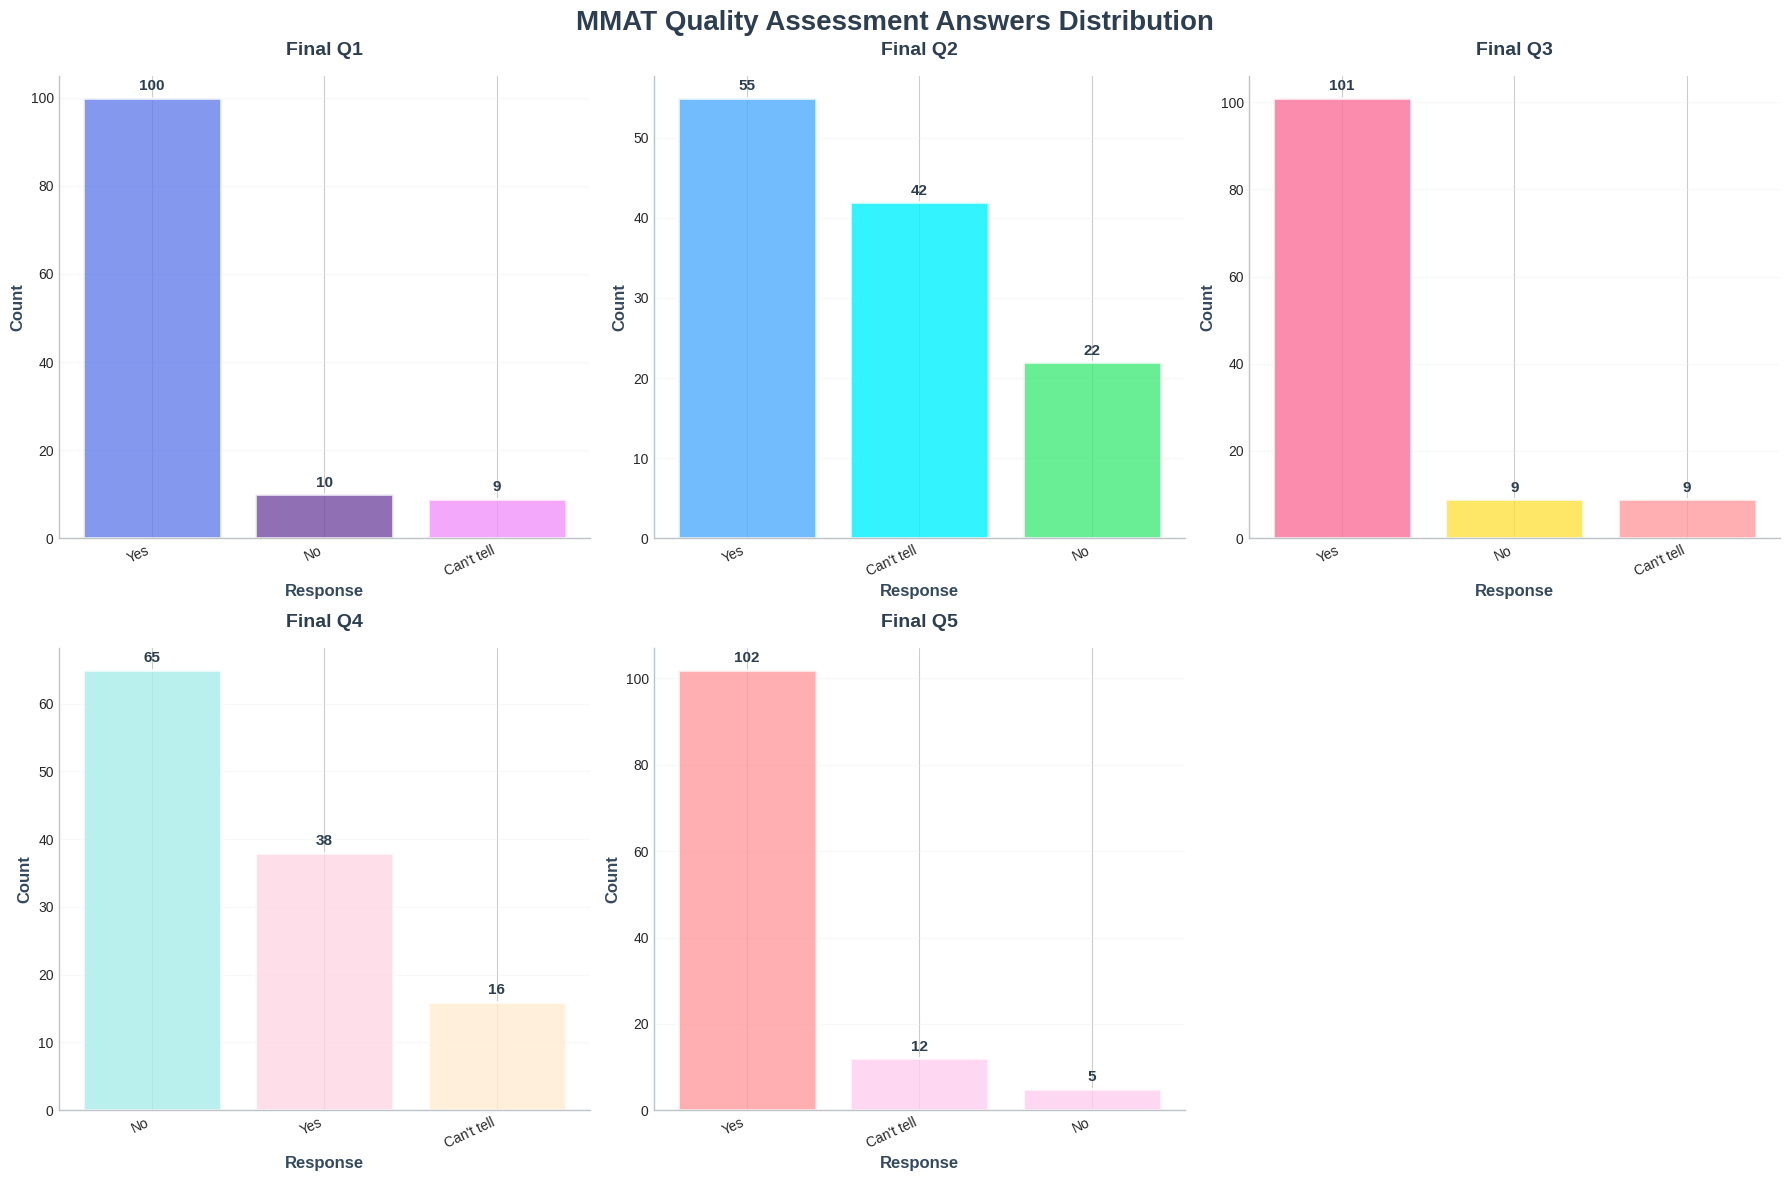

MMAT Answers Statistics:

final_q1:
final_q1
Yes           100
No             10
Can't tell      9
Name: count, dtype: int64
Total responses: 119
------------------------------

final_q2:
final_q2
Yes           55
Can't tell    42
No            22
Name: count, dtype: int64
Total responses: 119
------------------------------

final_q3:
final_q3
Yes           101
No              9
Can't tell      9
Name: count, dtype: int64
Total responses: 119
------------------------------

final_q4:
final_q4
No            65
Yes           38
Can't tell    16
Name: count, dtype: int64
Total responses: 119
------------------------------

final_q5:
final_q5
Yes           102
Can't tell     12
No              5
Name: count, dtype: int64
Total responses: 119
------------------------------


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

def create_mmat_visualizations(df):
    """
    Create 5 beautiful charts for MMAT answer columns
    """

    # MMAT answer columns
    mmat_columns = [
        'final_q1',
        'final_q2',
        'final_q3',
        'final_q4',
        'final_q5'
    ]

    # Set modern style
    plt.style.use('seaborn-v0_8-whitegrid')

    # Create figure with subplots
    fig, axes = plt.subplots(2, 3, figsize=(18, 12))
    axes = axes.flatten()

    # Color palettes for each chart
    color_palettes = [
        ['#667eea', '#764ba2', '#f093fb'],  # Purple-Blue gradient
        ['#4facfe', '#00f2fe', '#43e97b'],  # Blue-Green gradient
        ['#fa709a', '#fee140', '#ff9a9e'],  # Pink-Yellow gradient
        ['#a8edea', '#fed6e3', '#ffecd2'],  # Soft pastels
        ['#ff9a9e', '#fecfef', '#fecfef']   # Pink tones
    ]

    for i, column in enumerate(mmat_columns):
        if column in df.columns:
            # Get value counts
            value_counts = df[column].value_counts()

            # Select colors for this chart
            colors = color_palettes[i][:len(value_counts)]

            # Create bar chart
            bars = axes[i].bar(range(len(value_counts)),
                              value_counts.values,
                              color=colors,
                              alpha=0.8,
                              edgecolor='white',
                              linewidth=2)

            # Add value labels on bars
            for j, (bar, value) in enumerate(zip(bars, value_counts.values)):
                height = bar.get_height()
                axes[i].text(bar.get_x() + bar.get_width()/2.,
                           height + max(value_counts.values) * 0.01,
                           f'{value:,}',
                           ha='center', va='bottom',
                           fontweight='bold', fontsize=11, color='#2c3e50')

            # Styling for each subplot
            axes[i].set_title(f'{column.replace("_", " ").title()}',
                            fontsize=14, fontweight='bold', pad=15, color='#2c3e50')
            axes[i].set_xlabel('Response', fontsize=12, fontweight='600', color='#34495e')
            axes[i].set_ylabel('Count', fontsize=12, fontweight='600', color='#34495e')

            # Set x-axis labels
            axes[i].set_xticks(range(len(value_counts)))
            axes[i].set_xticklabels(value_counts.index, rotation=25, ha='right', fontsize=10)

            # Remove spines
            axes[i].spines['top'].set_visible(False)
            axes[i].spines['right'].set_visible(False)
            axes[i].spines['left'].set_color('#bdc3c7')
            axes[i].spines['bottom'].set_color('#bdc3c7')

            # Style grid
            axes[i].grid(axis='y', alpha=0.4, linestyle='-', linewidth=0.8, color='#ecf0f1')
            axes[i].set_axisbelow(True)

    # Remove the empty 6th subplot
    fig.delaxes(axes[5])

    # Overall title
    fig.suptitle('MMAT Quality Assessment Answers Distribution',
                 fontsize=20, fontweight='bold', color='#2c3e50', y=0.98)

    plt.tight_layout()
    return plt
# Usage examples:
# For all 5 charts together:
create_mmat_visualizations(df)
plt.show()



# Quick function to show statistics
def show_mmat_statistics(df):
    """
    Display statistics for all MMAT answer columns
    """
    mmat_columns = [
        'final_q1',
        'final_q2',
        'final_q3',
        'final_q4',
        'final_q5'
    ]

    print("MMAT Answers Statistics:")
    print("=" * 50)

    for column in mmat_columns:
        if column in df.columns:
            print(f"\n{column}:")
            print(df[column].value_counts())
            print(f"Total responses: {df[column].count()}")
            print("-" * 30)

# Usage:
show_mmat_statistics(df)

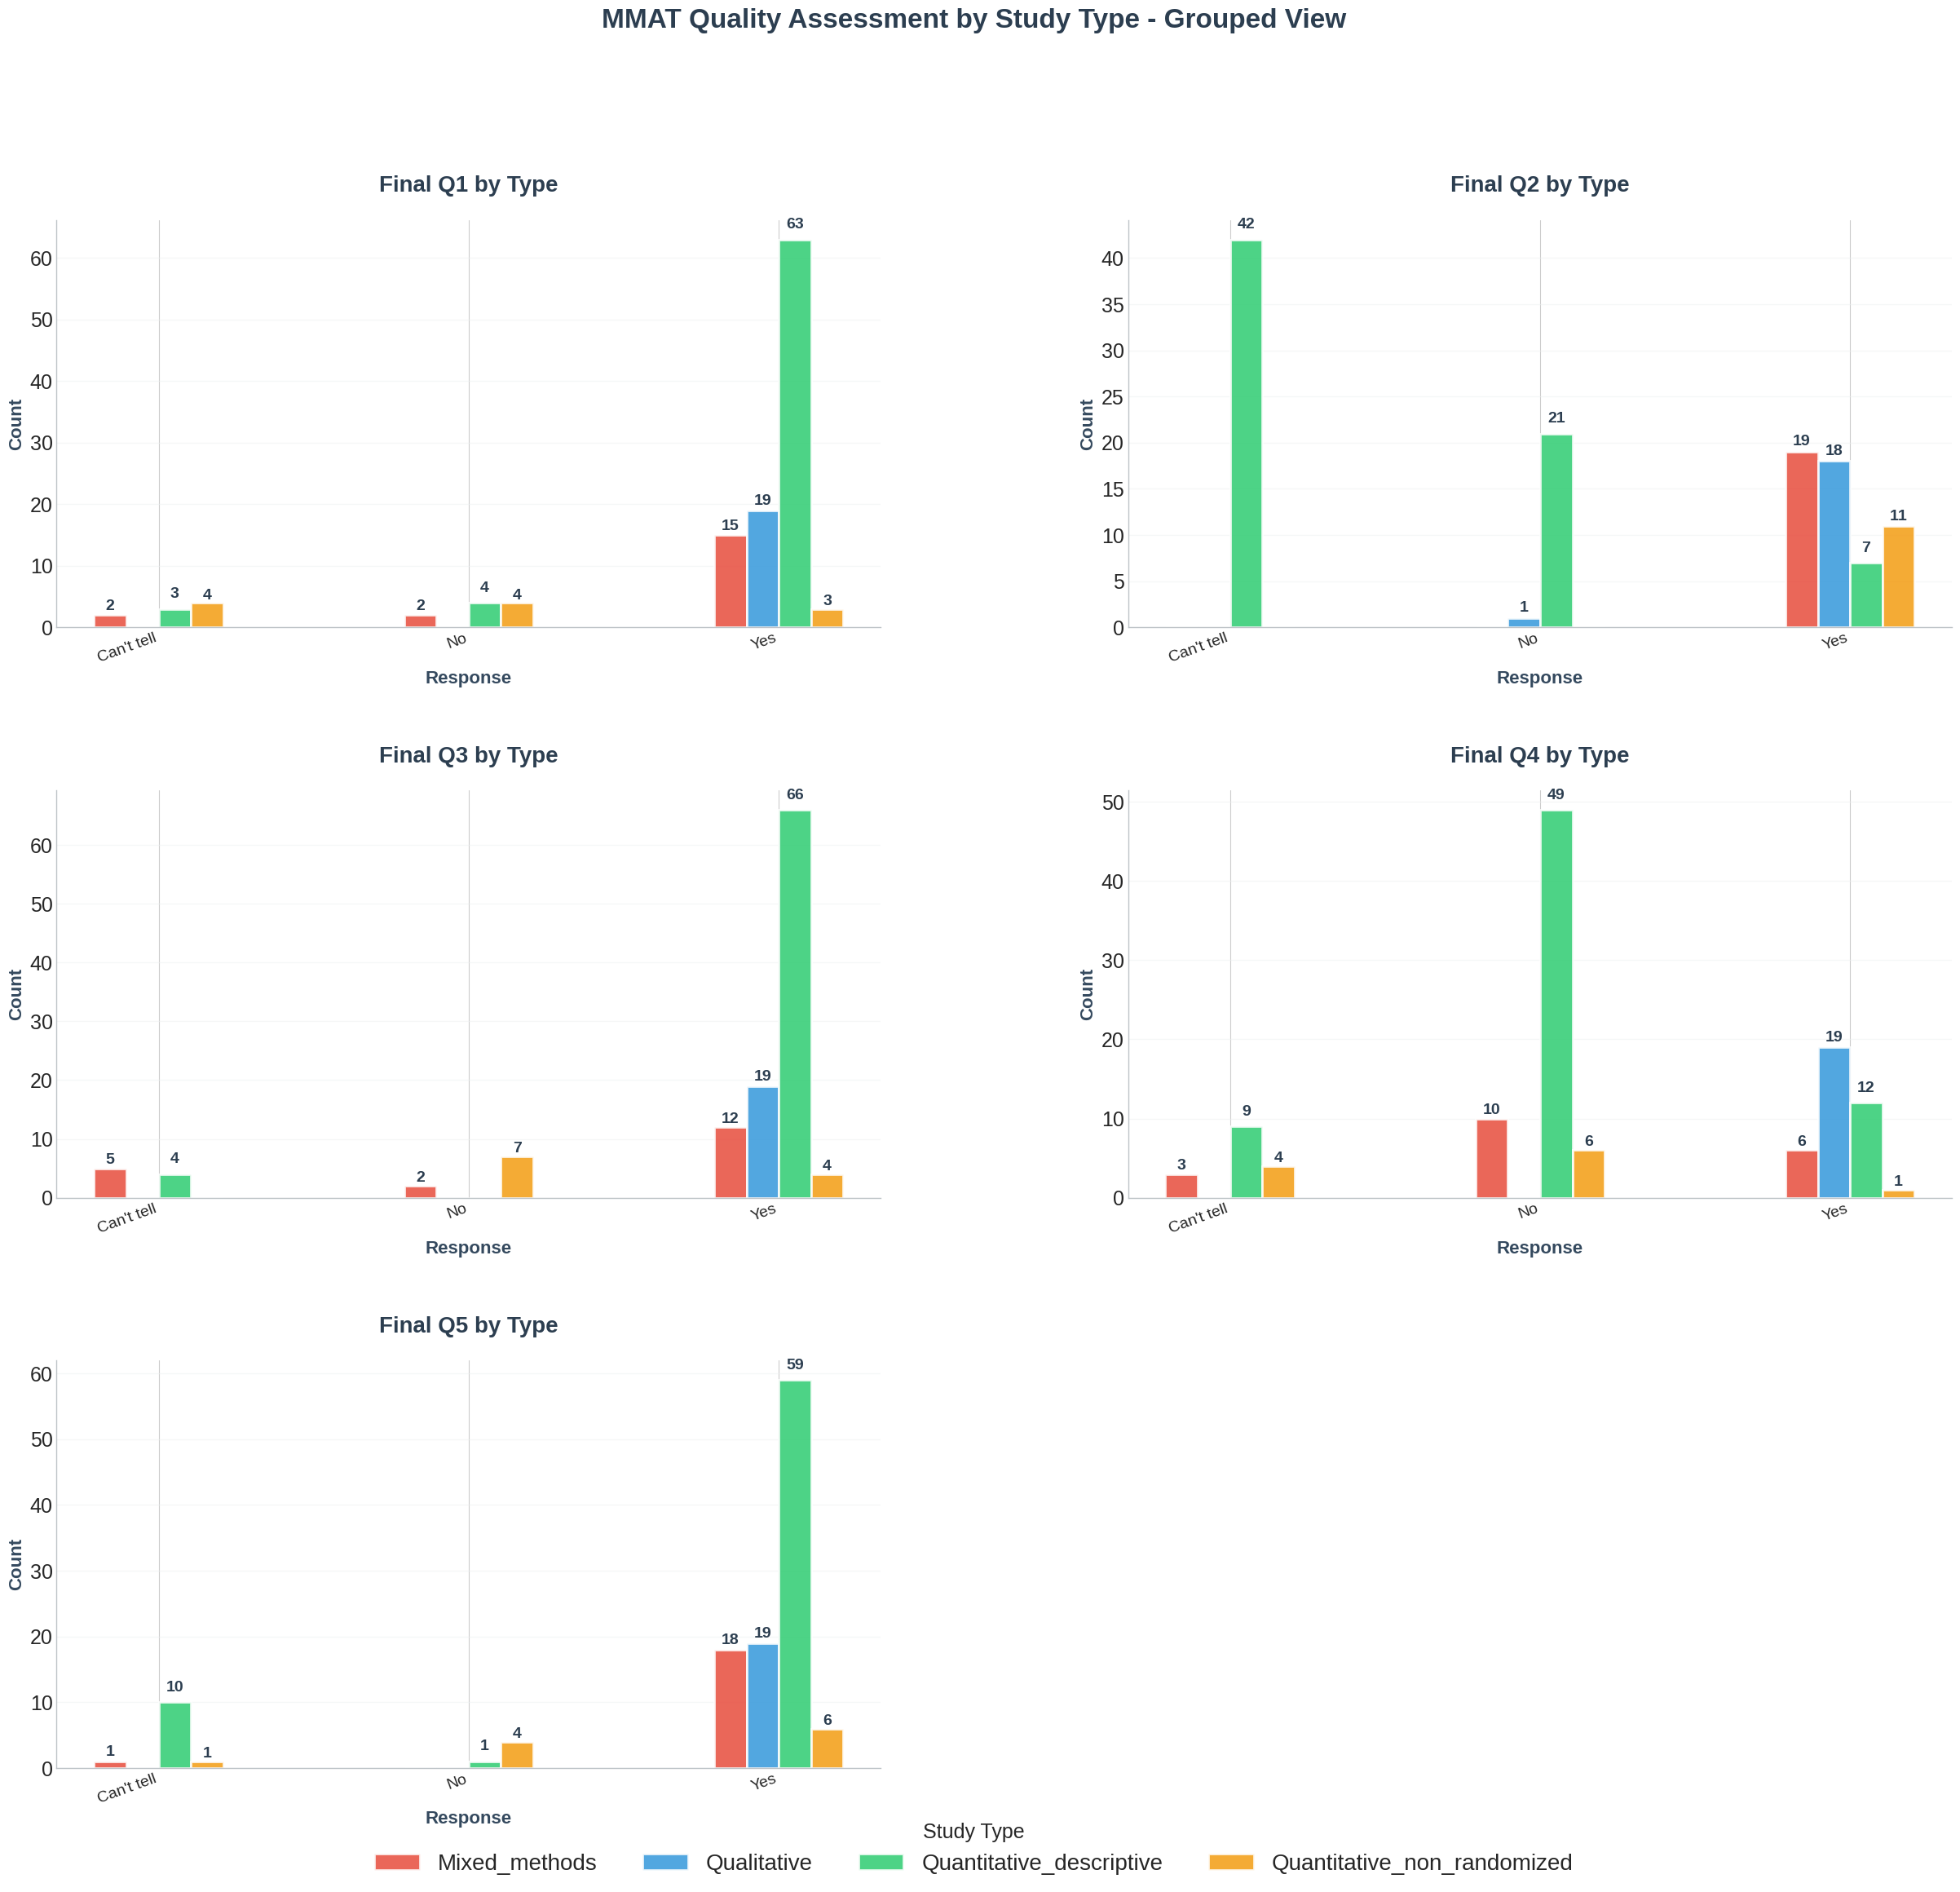

In [ ]:
def create_grouped_mmat_by_type(df):
    mmat_columns = [
        'final_q1',
        'final_q2',
        'final_q3',
        'final_q4',
        'final_q5'
    ]


    plt.style.use('seaborn-v0_8-whitegrid')
    fig, axes = plt.subplots(3, 2, figsize=(30, 26))
    axes = axes.flatten()

    unique_types = df['Type'].unique()
    colors = ['#e74c3c', '#3498db', '#2ecc71', '#f39c12', '#9b59b6',
              '#1abc9c', '#34495e', '#e67e22', '#95a5a6', '#16a085']

    legend_handles = []
    legend_labels = []

    for i, column in enumerate(mmat_columns):
        if column in df.columns and 'Type_final' in df.columns:
            crosstab = pd.crosstab(df['Type_final'], df[column])
            x = np.arange(len(crosstab.columns)) * 1.2
            width = 0.5 / len(crosstab.index)

            for j, (type_name, row) in enumerate(crosstab.iterrows()):
                offset = width * j - (width * len(crosstab.index) - width) / 2
                bars = axes[i].bar(x + offset, row.values, width,
                                   label=type_name, color=colors[j % len(colors)],
                                   alpha=0.85, edgecolor='white', linewidth=2)

                if i == 0:
                    legend_handles.append(bars[0])
                    legend_labels.append(type_name)

                for bar in bars:
                    height = bar.get_height()
                    if height > 0:
                        axes[i].text(bar.get_x() + bar.get_width()/2., height + max(row.values) * 0.02,
                                     f'{int(height)}', ha='center', va='bottom',
                                     fontweight='bold', fontsize=14, color='#2c3e50')

            axes[i].set_title(f'{column.replace("_", " ").title()} by Type', fontsize=20, fontweight='bold', pad=25, color='#2c3e50')
            axes[i].set_xlabel('Response', fontsize=16, fontweight='600', color='#34495e')
            axes[i].set_ylabel('Count', fontsize=16, fontweight='600', color='#34495e')
            axes[i].set_xticks(x)
            axes[i].set_xticklabels(crosstab.columns, rotation=20, ha='right', fontsize=14)
            axes[i].tick_params(axis='y', labelsize=18)
            axes[i].spines['top'].set_visible(False)
            axes[i].spines['right'].set_visible(False)
            axes[i].spines['left'].set_color('#bdc3c7')
            axes[i].spines['bottom'].set_color('#bdc3c7')
            axes[i].grid(axis='y', alpha=0.5, linestyle='-', linewidth=1, color='#ecf0f1')
            axes[i].set_axisbelow(True)

    fig.delaxes(axes[5])

    fig.legend(legend_handles, legend_labels, title='Study Type',
               title_fontsize=18, fontsize=20, loc='lower center', ncol=len(legend_labels),
               frameon=False, bbox_to_anchor=(0.5, 0.09))

    fig.suptitle('MMAT Quality Assessment by Study Type - Grouped View',
                 fontsize=24, fontweight='bold', color='#2c3e50', y=0.98)

    plt.subplots_adjust(hspace=0.4, wspace=0.3, bottom=0.15)
    return plt
create_grouped_mmat_by_type(df)
plt.show()

In [ ]:
df.to_excel("output_file.xlsx", index=False)

In [ ]:
def count_yes_answers(questions):
    yes_count = 0
    for question, question_data in questions.items():
        # Check both "answer": "Yes" and "Answer: Yes" in the raw response
        if '"answer": "Yes"' in question_data["raw_response"] or "Answer: Yes" in question_data["raw_response"] or "Answer: \nYes" in question_data["raw_response"]:
            yes_count += 1
    return yes_count


In [ ]:
cols_to_check = ['final_q1', 'final_q2', 'final_q3', 'final_q4', 'final_q5']

# Count how many "Yes" values per row
df["yes_count"] = df[cols_to_check].apply(
    lambda row: sum(str(val).strip().lower() == "yes" for val in row),
    axis=1
)


def quality_label(count: int) -> str:
    if count >= 4:
        return "High Quality"
    elif count == 3:
        return "Moderate Quality"
    else:
        return "Low Quality"

df["quality_label"] = df["yes_count"].apply(quality_label)


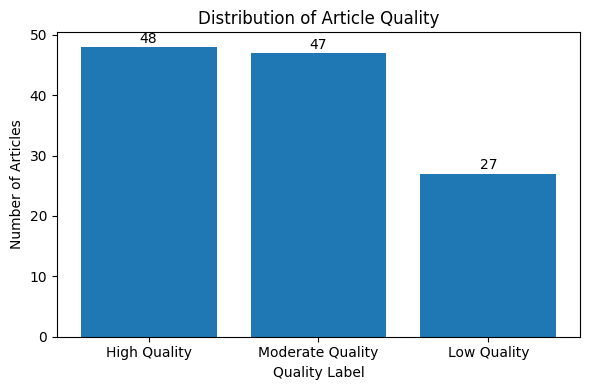

In [ ]:
import matplotlib.pyplot as plt

# Count how many rows fall into each quality_label
quality_counts = df["quality_label"].value_counts()

# Create a simple bar plot
plt.figure(figsize=(6,4))
bars = plt.bar(quality_counts.index, quality_counts.values)

# Add value labels on top of bars
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.2, int(yval), ha='center', va='bottom')

plt.title("Distribution of Article Quality")
plt.xlabel("Quality Label")
plt.ylabel("Number of Articles")
plt.tight_layout()
plt.show()


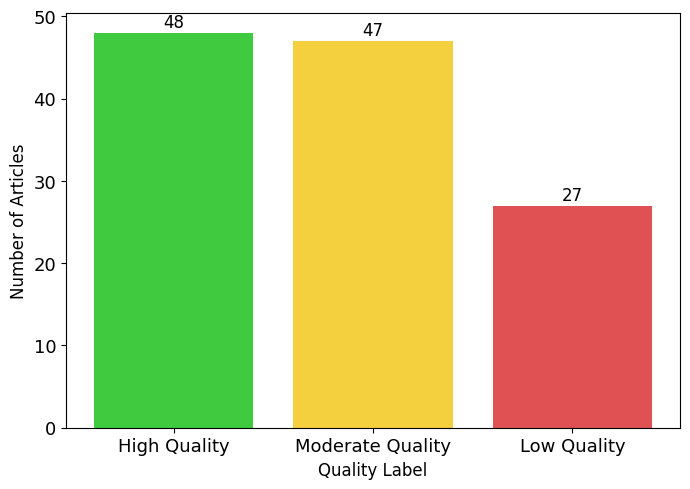

In [ ]:
import matplotlib.pyplot as plt

# Count how many rows fall into each quality_label
quality_counts = df["quality_label"].value_counts()

# Define the same bright colors used in the stacked bar and bubble chart
# color_map = {
#     "High Quality": "#7DFFB3",
#     "Moderate Quality": "#FFE680",
#     "Low Quality": "#FF6F6F"
# }
def lighten(color, amount=0.4):
    import matplotlib.colors as mc
    import colorsys
    try:
        c = mc.cnames[color]
    except:
        c = color
    c = colorsys.rgb_to_hls(*mc.to_rgb(c))
    new_c = colorsys.hls_to_rgb(c[0], min(1, amount * c[1] + (1-amount)), c[2])
    return new_c

tab10 = plt.cm.tab10
color_map = {
    "High Quality": lighten(tab10(2), 0.8),
    "Moderate Quality": lighten("#F1C40F", 0.8),
    "Low Quality": lighten(tab10(3), 0.8)
}

# Extract colors in the order of the index
bar_colors = [color_map[label] for label in quality_counts.index]

# Create a simple bar plot
plt.figure(figsize=(7,5))
bars = plt.bar(quality_counts.index, quality_counts.values, color=bar_colors)

# Add value labels on top of bars
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.2, int(yval),
             ha='center', va='bottom', fontsize=12)

# plt.title("Distribution of Article Quality", fontsize=14, fontweight='bold')
plt.xlabel("Quality Label", fontsize=12)
plt.ylabel("Number of Articles", fontsize=12)

plt.xticks(fontsize=13)
plt.yticks(fontsize=13)

plt.tight_layout()
plt.savefig("Quality.png", dpi=600, bbox_inches="tight")

plt.show()


In [ ]:
df[['PubMed ID', 'DOI', 'Title', 'Year',
       'Abstract','Matching_Filename','Type_final','yes_count',
       'quality_label']].to_excel("/content/drive/MyDrive/fix_systematic_review/goal/mmat_final.xlsx", index=False)